# Retargetable complex QSP dynamics

The fixed local chain is $H=\sum Z_jZ_{j+1}+0.7\sum X_j$, with $\hbar=1$. This notebook chooses two spins, $t=0.5$ and known input $|00\rangle$. Its target is $e^{-iHt}|00\rangle$, or an accepted measured $Z_0$ trial. The requested **declared logical-source** decoded operator error is $10^{-5}$.

Actual phases are generated for $\tau=\alpha t$ rather than reusing a frozen $4.1$ table. A separate directed-interval coefficient validator checks the stored phases and scalar target. A separate directed weight validator encloses the actual RY/X coefficient loader, and exact-rational parameter rounding is included. The combined certificate applies to declared logical controls and stored binary64 angles; floating nested-control definitions, compiler transformations, synthesis and physical faults require separate realization contracts. All code and figures are original MIT work using the pinned Qiskit/SciPy environment.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import Operator

root = Path.cwd()
if not (root / "retargetable_qsp.py").exists() and not (root / "src/openquantum/simulation/retargetable_qsp.py").exists() and (root.parent / "src/openquantum/simulation/retargetable_qsp.py").exists():
    root = root.parent
if not (root / "retargetable_qsp.py").exists() and (root / "src/openquantum/simulation/retargetable_qsp.py").exists():
    sys.path.insert(0, str(root / "src"))
    sys.path.insert(0, str(root / "scripts"))
    from openquantum import hamiltonian_simulation as hs
    from openquantum.simulation import retargetable_qsp as rq
    from openquantum.simulation.qsp_phase_generation import real_qsp_response
else:
    # Save every copied source and generator beside this notebook.
    sys.path.insert(0, str(root))
    import hamiltonian_simulation as hs
    import retargetable_qsp as rq
    from qsp_phase_generation import real_qsp_response
import generate_simulation_retargetable_qsp as artifacts
# Generator imports select Agg; restore notebook figure rendering.
get_ipython().run_line_magic("matplotlib", "inline")

terms = hs.spin_terms(2, 1.0, 0.7)
time = 0.5
requested_error = 1e-5
tau = sum(abs(c) for c, _ in terms) * time
plan = rq.generate_dynamics_phases(tau, requested_error)
core = rq.build_retargetable_evolution(terms, time, requested_error, phase_plan=plan)
compiled = rq.lower_circuit(core)
trial = rq.lower_circuit(rq.build_measured_trial(core))
check = rq.compare_evolution(core, terms, time, full_operator=True)
ledger = rq.logical_ledger(compiled, trial, acceptance=check["acceptance_probability"])
assert plan.decoded_polynomial_error_upper <= requested_error
assert check["decoded_operator_error"] < requested_error
print(f"tau={tau:g}; degrees {plan.even_degree}/{plan.odd_degree}; {core.num_qubits} logical wires")
print(f"Ideal-polynomial decoded error bound: {plan.decoded_polynomial_error_upper:.3e}")
assert core.metadata["logical_source_certificate"]["decoded_operator_error_upper"] <= requested_error


tau=1.2; degrees 6/7; 6 logical wires
Ideal-polynomial decoded error bound: 8.574e-07


## Actual access and parity selector

PREPARE loads $\sqrt{|h_j|/\alpha}$ into binary labels, signed SELECT applies the Pauli term, and inverse PREPARE completes a Hermitian block of $H/\alpha$. Real QSP phases transform its signal into an even cosine/2 and odd sine/2 polynomial. An actual selector with relative $-i$ combines the parities:

$$K(x)=\frac{P_c(x)-iP_s(x)}2\approx\frac{e^{-i\tau x}}4.$$

The defined boxes below contain actual gate circuits. Every projector phase, ordinary access and the extra selector-controlled odd access is present. The downloadable measured QASM lowers their bodies to primitive operations.

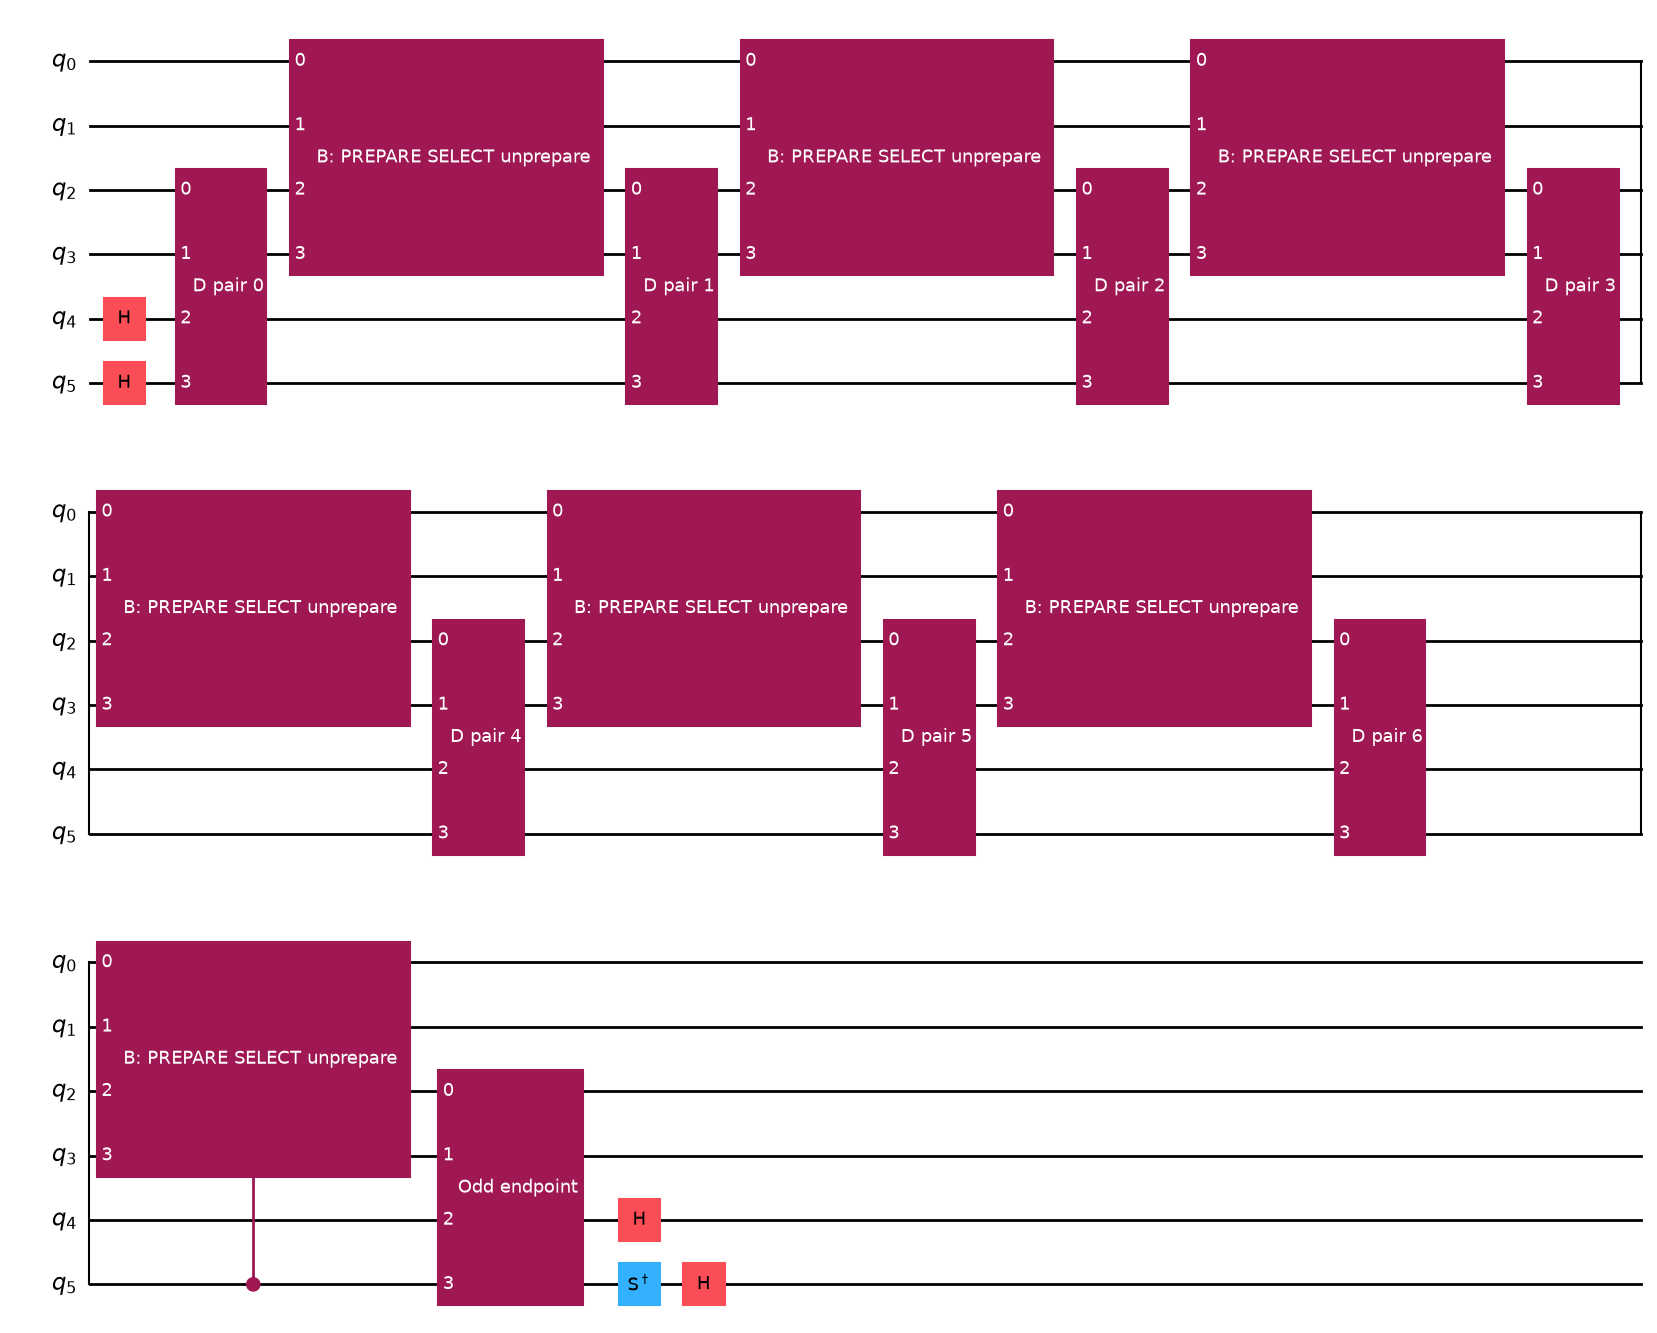

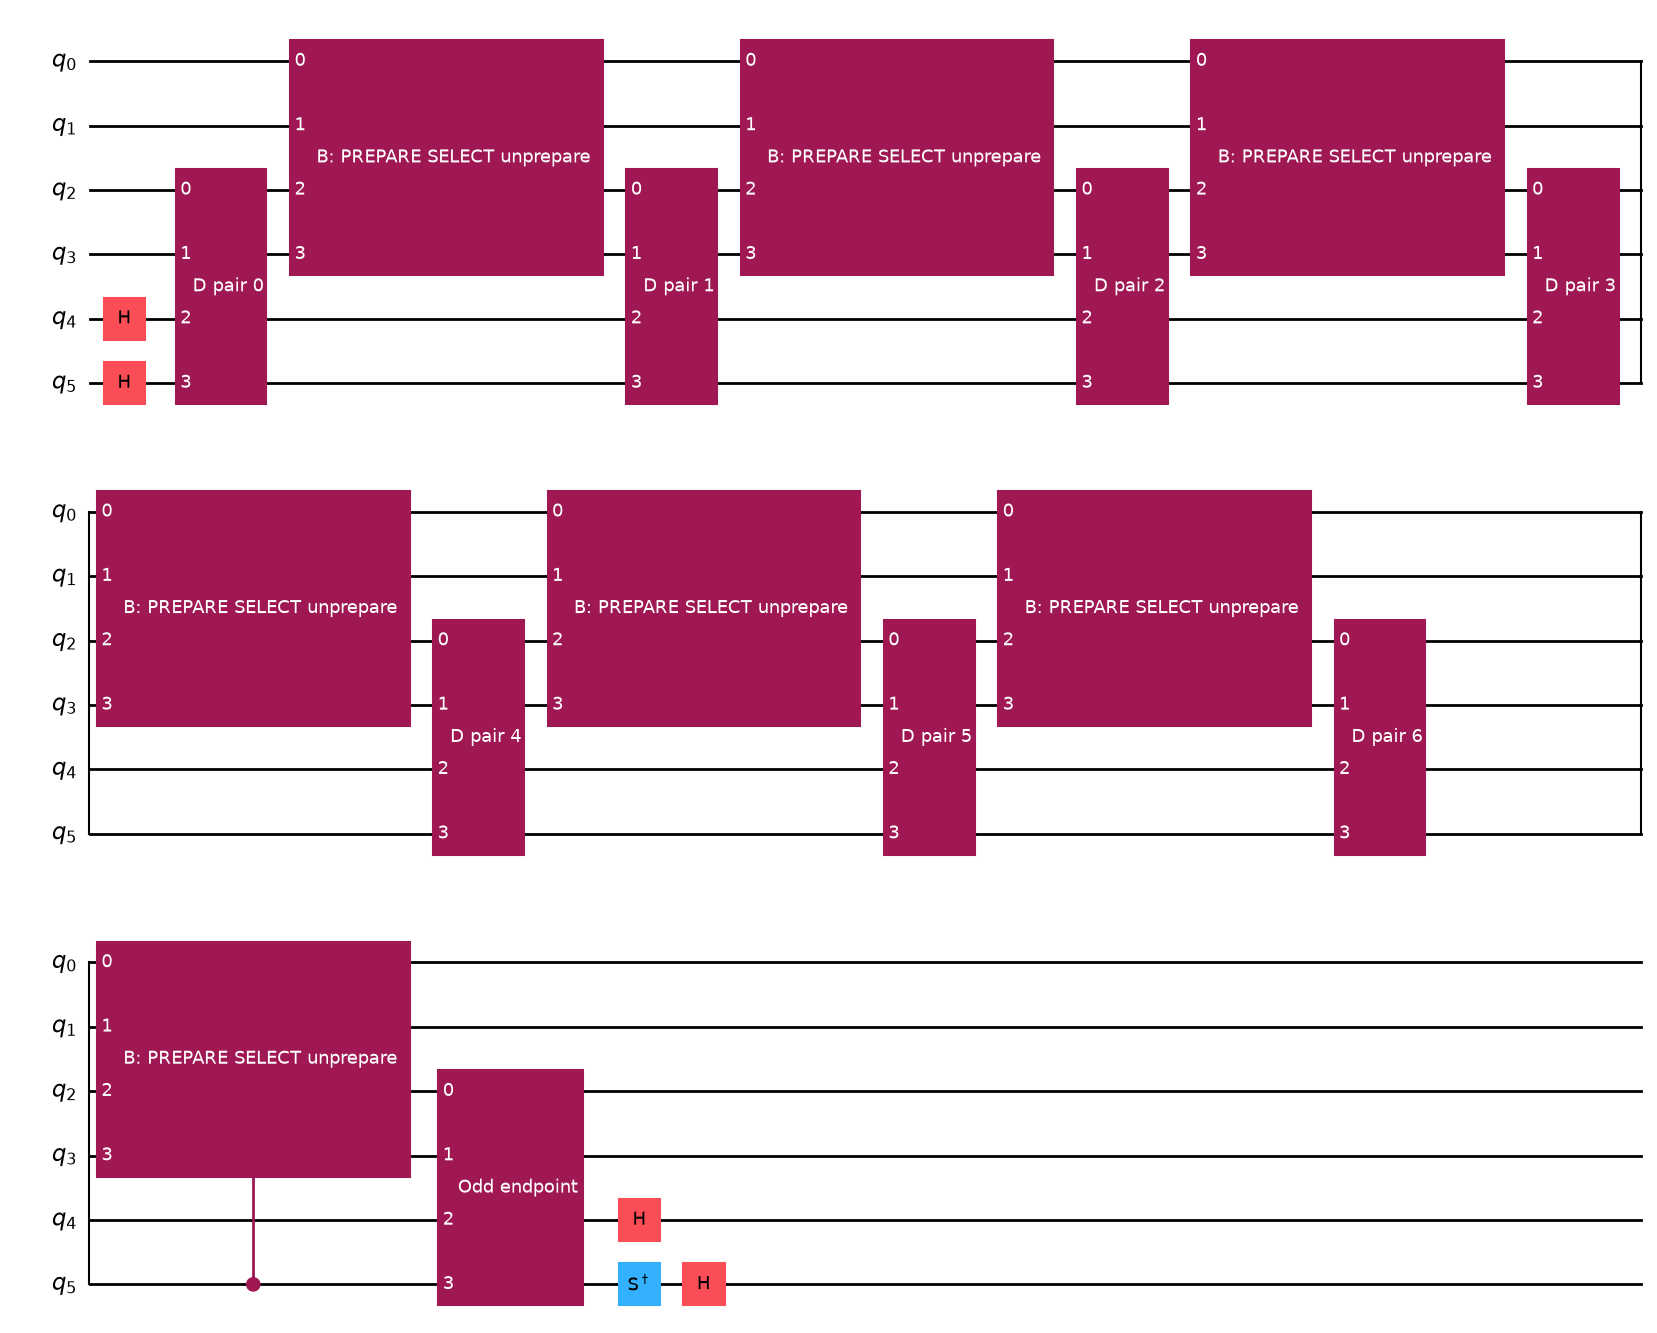

In [2]:
diagram = artifacts.circuit_diagram(core, plan, terms)
assert np.max(np.abs(Operator(diagram).data-Operator(core).data)) < 5e-12
diagram.draw(output="mpl", fold=24)

## Fitting and interval validation are separate

The phase solver uses a bounded, seeded nonlinear fit with an analytic Jacobian. Its node/grid residual is numerical evidence. The separate validator uses directed decimal intervals to enclose the exact ideal signal-polynomial coefficients for the stored binary64 phases and parameter, then bounds coefficient error and an analytic target tail.

The displayed source bound adds exact-rational normalization/time mismatch and a directed PREPARE weight error to the ideal polynomial bound. Negative signs use exact named Clifford patterns. Stored RY angles are interpreted as exact real binary64 values in this logical model. Floating nested ControlledGate/MCX definitions and final primitive transformations are checked numerically but are outside the certificate, as are synthesis and reset/readout faults. A large-system grid is never substituted for this interval coefficient check.

In [3]:
certificate_rows = [
    {"quantity":"Cosine ideal uniform error upper", "value":plan.cosine_certificate["uniform_error_upper"]},
    {"quantity":"Sine ideal uniform error upper", "value":plan.sine_certificate["uniform_error_upper"]},
    {"quantity":"Decoded ideal polynomial error upper", "value":plan.decoded_polynomial_error_upper},
    {"quantity":"Parameter mismatch operator upper", "value":core.metadata["parameter_mismatch_operator_error_upper"]},
    {"quantity":"Combined ideal error with parameter rounding", "value":core.metadata["ideal_signal_decoded_error_upper_with_parameter_rounding"]},
    {"quantity":"Normalization summation rounding diagnostic", "value":core.metadata["normalization_sum_rounding_absolute"]},
    {"quantity":"Normalization-time rounding diagnostic", "value":core.metadata["normalization_time_rounding_absolute"]},
]
source_certificate=core.metadata["logical_source_certificate"]
certificate_rows += [
    {"quantity":"PREPARE weight l1 upper", "value":source_certificate["prepared_weight_certificate"]["weight_l1_error_upper"]},
    {"quantity":"Decoded declared logical-source error upper", "value":source_certificate["decoded_operator_error_upper"]},
    {"quantity":"Declared source uniform acceptance lower", "value":source_certificate["uniform_acceptance_lower"]},
]
display(pd.DataFrame(certificate_rows))
print(source_certificate["scope"])

,quantity,value
0,Cosine ideal uniform error upper,4.018222e-07
1,Sine ideal uniform error upper,2.687626e-08
2,Decoded ideal polynomial error upper,8.573970e-07
3,Parameter mismatch operator upper,0.000000e+00
4,Combined ideal error with parameter rounding,8.573970e-07
5,Normalization summation rounding diagnostic,0.000000e+00
6,Normalization-time rounding diagnostic,0.000000e+00
7,PREPARE weight l1 upper,5.402377e-17
8,Decoded declared logical-source error upper,8.573970e-07
9,Declared source uniform acceptance lower,6.249989e-02


declared logical source for exact real input numbers represented by supplied binary64 coefficients/time, exact named Cliffords, conditional controls and stored rotation angles; exact signed SELECT and interval-enclosed PREPARE weights; polynomial, loading and parameter errors combined by functional calculus and Duhamel. External model-to-input representation, floating nested ControlledGate/MCX realization, compiler/synthesis and physical faults are separate


## Circuit state, operator and readout checks

The actual coherent circuit is compared with an independently assembled Pauli Hamiltonian and SciPy matrix exponential. These matrices are bounded classical answers and are never circuit gates. The normalized conditional state is checked **before system readout**. The measured export returns classical system bits only when every access/flag/selector bit is zero.

Acceptance is nearly $1/16$ rather than one. The finite-instance singular values and the zero-input probability are separate from the ideal-signal certificate. Failed trials require a fresh complete known-input preparation.

In [4]:
keys = ["encoded_block_operator_error", "decoded_operator_error", "conditional_state_vector_error", "conditional_state_infidelity", "Z_exact", "Z_conditional", "Z_bias", "acceptance_probability", "finite_instance_minimum_acceptance", "finite_instance_maximum_acceptance"]
display(pd.DataFrame([{"quantity":k,"value":check[k]} for k in keys]))
assert np.max(np.abs(Operator(core).data-Operator(compiled).data)) < 5e-12

,quantity,value
0,encoded_block_operator_error,1.990372e-07
1,decoded_operator_error,7.961489e-07
2,conditional_state_vector_error,7.788896e-07
3,conditional_state_infidelity,6.066259e-13
4,Z_exact,7.836361e-01
5,Z_conditional,7.836358e-01
6,Z_bias,3.028150e-07
7,acceptance_probability,6.250001e-02
8,finite_instance_minimum_acceptance,6.249993e-02
9,finite_instance_maximum_acceptance,6.250009e-02


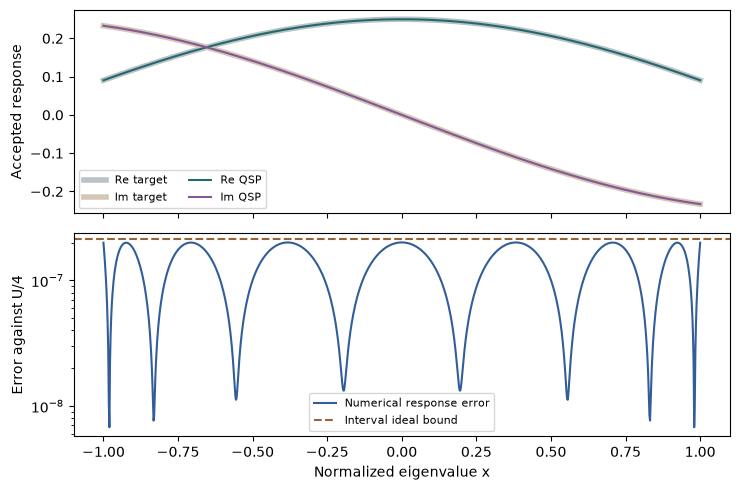

In [5]:
x = np.linspace(-1,1,1001)
actual = (real_qsp_response(x,plan.cosine_phases)-1j*real_qsp_response(x,plan.sine_phases))/2
target = np.exp(-1j*tau*x)/4
fig, axes = plt.subplots(2,1,figsize=(7.5,5),sharex=True)
axes[0].plot(x,target.real,color="#bac3c6",lw=4,label="Re target")
axes[0].plot(x,target.imag,color="#d5c7b8",lw=4,label="Im target")
axes[0].plot(x,actual.real,color="#24686e",label="Re QSP")
axes[0].plot(x,actual.imag,color="#845896",label="Im QSP")
axes[0].set(ylabel="Accepted response"); axes[0].legend(ncol=2,fontsize=8)
axes[1].semilogy(x,np.maximum(np.abs(actual-target),1e-18),color="#315e99",label="Numerical response error")
axes[1].axhline(plan.encoded_polynomial_error_upper,color="#996335",ls="--",label="Interval ideal bound")
axes[1].set(xlabel="Normalized eigenvalue x",ylabel="Error against U/4"); axes[1].legend(fontsize=8)
fig.tight_layout()

## Complete attempts and logical workload

A complete measured attempt resets all wires, prepares the known basis input, performs every access and phase operation, and measures every wire. Counts include those resets and readout gates. The logical depth is a dependency-layer count, with physical timing excluded.

One accepted trial at 1% no-acceptance failure uses a capped number of full attempts. A separate proposed $Z_0$ mean uses 13,315 accepted samples for statistical error0.03/failure0.005 and its own acceptance-failure allocation. Both workloads are unexecuted proposals. Synthesis norm error and physical faults remain distinct.

In [6]:
display(pd.DataFrame([{"gate":g,"per_complete_attempt":c} for g,c in ledger["full_trial_primitive_counts"].items()]))
print("Depth",ledger["full_trial_dependency_depth"],"initial resets",ledger["initial_resets"],"measurements",ledger["final_measurements"])
print(ledger["postselection_retry"])
workload = artifacts.workload_projection(check["acceptance_probability"], ledger["full_trial_primitive_counts"], trial.depth(), trial.num_qubits)
print("Accepted samples:",workload["required_accepted_Z_samples"],"cap per slot:",workload["complete_attempt_cap_per_slot"],"complete attempt cap:",workload["complete_attempt_cap_all_slots"])

,gate,per_complete_attempt
0,cx,648
1,t,301
2,tdg,246
3,rz,200
4,h,108
5,ry,78
6,x,65
7,reset,6
8,rx,6
9,measure,6


Depth 1185 initial resets 6 measurements 6
{'model': 'state-specific numerical precompiler acceptance; compiled/synthesized/physical errors remain separate', 'probability': 0.06250000870777492, 'one_accepted_trial_failure_target': 0.01, 'one_accepted_trial_cap': 72, 'expected_complete_attempts': 15.999997770809932}
Accepted samples: 13315 cap per slot: 230 complete attempt cap: 3062450


## Fixed local couplings across sizes and times

The generator varies $n$ and $t$ while keeping $J=1,h=0.7$. Its $\alpha_n=(n-1)+0.7n$ grows with size, and each resulting $\tau_n=\alpha_nt$ gets new fitted and interval-validated phases. Degree, logical count and depth are measured for the selected requested declared-source allowance, including interval loading error. Floating nested-control/primitive realization, synthesis and a physical equal-accuracy advantage remain outside those counts and bounds.

The table below is read from the independently executed canonical generator bundle; standalone code can omit it when those optional result files are absent.

In [7]:
asset_dir = root / "assets/generated/simulation/retargetable-qsp"
if not asset_dir.exists():
    asset_dir = root
csv_path = asset_dir / "scaling.csv"
if csv_path.exists():
    table = pd.read_csv(csv_path)
    display(table[["n_system","time","alpha","tau","even_degree","odd_degree","logical_qubits","full_trial_operations","full_trial_dependency_depth","decoded_logical_source_error_upper","simulation_performed"]])
else:
    print("Optional canonical sweep CSV not present; use the standalone generator to reproduce it.")

,n_system,time,alpha,tau,even_degree,odd_degree,logical_qubits,full_trial_operations,full_trial_dependency_depth,decoded_logical_source_error_upper,simulation_performed
0,2,0.50,2.4,1.200,6,7,6,1665,1185,8.573970e-07,True
1,1,0.50,0.7,0.350,4,5,3,109,93,8.146881e-08,True
2,3,0.50,4.1,2.050,8,9,8,6248,4728,7.068347e-07,True
3,1,0.25,0.7,0.175,4,5,3,109,93,1.261032e-09,True
4,1,1.00,0.7,0.700,6,7,3,145,125,1.146354e-08,True
5,2,0.25,2.4,0.600,4,5,6,1357,977,2.088257e-06,True
6,2,1.00,2.4,2.400,10,11,6,2281,1601,3.669981e-08,True


## Reproduction and scope

Use the locked Python3.12 environment. Save this notebook, the standalone generator, `retargetable_qsp.py`, `qsp_phase_generation.py`, `qsp_certificate.py`, `artifact_provenance.py`, `lcu.py` and `hamiltonian_simulation.py` together. Source and phase hashes, parameters, package versions and CPU timings are recorded in the generated bundle.

`--no-sim` still generates and validates phases; it skips quantum state/operator checks and empirical acceptance/workload claims. The larger bounded example is `--qubits 8 --time 0.5 --no-sim --no-sweep`. Materialization, phase fitting, interval validation and simulator caps are separate and fail closed. General unbounded phase synthesis, deterministic evolution, physical projections and formal/Lean proof remain planned. Static execution creates no widgets.